# Part 8: Sensitivity to the Window Length

### Ramith Vaid | NTU Singapore

Every result so far uses one design: five years of training data, then a six-month test window, rolled forward without overlap. Both lengths were chosen once and never varied. This part varies them, on the 8-stock universe:

- **Test (rebalance) window: 3, 6 and 12 months**, with five years of training. A shorter window means a fresher covariance estimate and more windows, but more rebalances and more cost. The DCC correlation forecast horizon is set to match the window.
- **Training window: 3, 5 and 7 years**, with a six-month test window.

For each configuration, from training data only: Max Sharpe with the sample covariance, the GARCH covariance with static correlation and the GARCH covariance with DCC correlation (each window's T-bill yield as the risk-free rate, 35% cap), plus equal weight rebalanced at the same frequency. Outcomes: the Part 1 to 4 metric (predicted against realized portfolio volatility, with and without the window that contains the COVID crash), and realized return, Sharpe against the T-bill return and turnover net of 10 bps costs.

**A comparability point.** Different window lengths cover different spans of time (more windows is not just more data: a 3-year training window starts testing in 2017, a 7-year one in 2021, and whole windows are cut off at the end). So the performance comparisons are made on the dates that every configuration in the comparison covers, and the volatility-error comparison reports each configuration's own windows. The data end date is pinned to 2026-10-13.

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from portfolio_utils import (
    max_sharpe_portfolio, portfolio_variance, load_or_build_window_inputs, window_risk_free,
    simulate_strategy_rf, risk_summary
)
print('Libraries loaded.')

Libraries loaded.


## 1. Data

In [2]:
tickers8 = ['JPM', 'AAPL', 'XOM', 'JNJ', 'PG', 'CAT', 'NEE', 'AMZN']
START, END = '2014-01-01', '2026-10-14'  # END is exclusive: last row is 2026-10-13
prices = pd.DataFrame({t: yf.download(t, start=START, end=END, progress=False)['Close'].squeeze() for t in tickers8}).dropna()
log_returns = np.log(prices / prices.shift(1)).dropna()
irx = yf.download('^IRX', start=START, end=END, progress=False)['Close'].squeeze().dropna()
tbill_annual = (irx / 100).clip(lower=0.0).reindex(log_returns.index).ffill().bfill()
rf_daily = tbill_annual / 252
print(f'{len(log_returns)} trading days, {log_returns.index[0].date()} to {log_returns.index[-1].date()}')

3213 trading days, 2014-01-03 to 2026-10-13


## 2. Per-window estimates for every configuration

Each configuration needs its own set of rolling windows, each with one GARCH model per asset and a DCC model. The six-month, five-year configuration is the one used throughout and is already cached; the others take several minutes each the first time (results are cached in git-ignored pickles).

In [3]:
CONFIGS = {
    'test 3m / train 5y':  dict(train_years=5, test_months=3),
    'test 6m / train 5y':  dict(train_years=5, test_months=6),
    'test 12m / train 5y': dict(train_years=5, test_months=12),
    'test 6m / train 3y':  dict(train_years=3, test_months=6),
    'test 6m / train 7y':  dict(train_years=7, test_months=6),
}
inputs = {}
for name, cfg in CONFIGS.items():
    path = 'cache_window_inputs_8.pkl' if (cfg['train_years'], cfg['test_months']) == (5, 6) else f'cache_inputs8_tr{cfg["train_years"]}_te{cfg["test_months"]}.pkl'
    inputs[name] = load_or_build_window_inputs(path, log_returns, tickers8, **cfg)
    w = inputs[name]
    print(f'{name:<22} {len(w):>3} windows; first test day {w[0]["test"].index[0].date()}, last {w[-1]["test"].index[-1].date()}')

test 3m / train 5y      31 windows; first test day 2019-01-07, last 2026-10-13
test 6m / train 5y      15 windows; first test day 2019-01-07, last 2026-07-15
test 12m / train 5y      7 windows; first test day 2019-01-07, last 2026-01-12
test 6m / train 3y      19 windows; first test day 2017-01-04, last 2026-07-15
test 6m / train 7y      11 windows; first test day 2021-01-06, last 2026-07-15


## 3. Predicted vs. realized portfolio volatility

Mean absolute gap between the volatility each covariance predicted for its Max Sharpe portfolio and the volatility realized over the window, over each configuration's own windows, with and without the window whose test period contains the COVID crash (March 2020). The paired t-statistic is over windows of the difference between the sample and the GARCH error.

In [4]:
KEYS = [('sample', 'Sample'), ('garch_static', 'GARCH static'), ('garch_dcc', 'GARCH DCC')]
def vol_errors(win):
    rows = []
    rf_win = window_risk_free(win, log_returns, tbill_annual)
    for wi, rf in zip(win, rf_win):
        row = {'window': wi['window'], 'test_start': wi['test_start'], 'covid': bool(wi['test'].index[0] <= pd.Timestamp('2020-03-23') and wi['test'].index[-1] >= pd.Timestamp('2020-03-01'))}
        for key, _ in KEYS:
            w = max_sharpe_portfolio(wi['mean'], wi['cov'][key], 8, rf=rf)
            pred = np.sqrt(portfolio_variance(w, wi['cov'][key].values))
            row[f'{key}_error'] = abs(pred - (wi['test'] @ w).std() * np.sqrt(252))
        rows.append(row)
    return pd.DataFrame(rows)

err = {n: vol_errors(w) for n, w in inputs.items()}
rows = []
for n, e in err.items():
    for label, mask in (('all windows', np.ones(len(e), bool)), ('excluding COVID window', ~e['covid'].values)):
        x = e[mask]
        r = {'config': n, 'windows': label, 'n': len(x)}
        for key, lab in KEYS:
            r[f'{lab} error %'] = x[f'{key}_error'].mean() * 100
        for key, lab in KEYS[1:]:
            d = x['sample_error'] - x[f'{key}_error']
            r[f'{lab} wins'] = int((d > 0).sum())
            r[f't (sample - {lab})'] = d.mean() / (d.std(ddof=1) / np.sqrt(len(d)))
        rows.append(r)
voltab = pd.DataFrame(rows)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
pd.set_option('display.width', 250)
print(voltab.to_string(index=False))
print()
print('Windows flagged as containing the COVID crash:', {n: int(e['covid'].sum()) for n, e in err.items()})

             config                windows  n  Sample error %  GARCH static error %  GARCH DCC error %  GARCH static wins  t (sample - GARCH static)  GARCH DCC wins  t (sample - GARCH DCC)
 test 3m / train 5y            all windows 31            7.03                  5.96               5.46                 20                       1.37              22                    1.92
 test 3m / train 5y excluding COVID window 30            5.85                  4.60               4.06                 20                       1.58              22                    2.19
 test 6m / train 5y            all windows 15            7.39                  6.24               5.93                 10                       1.18              11                    1.29
 test 6m / train 5y excluding COVID window 14            5.79                  4.32               3.94                 10                       1.49              11                    1.63
test 12m / train 5y            all windows  7          

## 4. Realized performance net of costs

Each configuration's strategies, run with 10 bps costs and the window's T-bill yield as the optimizer's risk-free rate. Daily returns are concatenated across windows. Because the configurations cover different spans, the table is computed on the dates covered by every configuration in the group: the test-length group (all three start at 2019-01-07, ending with the shortest) and the training-length group (from the latest start to the earliest end).

In [5]:
COST = 0.0010
daily = {}
turn = {}
for n, win in inputs.items():
    rf_win = window_risk_free(win, log_returns, tbill_annual)
    for key, label in [('sample', 'Sample'), ('garch_static', 'GARCH static'), ('garch_dcc', 'GARCH DCC'), ('equal_weight', 'Equal weight')]:
        wdf, net, gross, _ = simulate_strategy_rf(win, 8, key, COST, rf_win)
        daily[(n, label)] = net
        turn[(n, label)] = wdf['turnover'].iloc[1:].mean()

groups = {
    'test-window length (5y training)': ['test 3m / train 5y', 'test 6m / train 5y', 'test 12m / train 5y'],
    'training length (6m test)': ['test 6m / train 3y', 'test 6m / train 5y', 'test 6m / train 7y'],
}
rows = []
for gname, members in groups.items():
    start = max(daily[(m, 'Sample')].index[0] for m in members)
    end = min(daily[(m, 'Sample')].index[-1] for m in members)
    for m in members:
        for label in ['Sample', 'GARCH static', 'GARCH DCC', 'Equal weight']:
            r = daily[(m, label)].loc[start:end]
            s = risk_summary(r, rf_daily)
            rows.append({'group': gname, 'config': m, 'strategy': label, 'common_period': f'{start.date()} to {end.date()}', 'days': len(r),
                         'return_%': s['ann_return'] * 100, 'vol_%': s['ann_vol'] * 100, 'sharpe': s['sharpe'], 'max_dd_%': s['max_drawdown'] * 100,
                         'avg_turnover': turn[(m, label)]})
perf = pd.DataFrame(rows)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
for gname in groups:
    print(f'--- {gname}: {perf[perf.group == gname].common_period.iloc[0]} ---')
    print(perf[perf.group == gname].drop(columns=['group', 'common_period']).to_string(index=False))
    print()

--- test-window length (5y training): 2019-01-07 to 2026-01-12 ---
             config     strategy  days  return_%  vol_%  sharpe  max_dd_%  avg_turnover
 test 3m / train 5y       Sample  1764    14.619 21.274   0.562   -28.141         0.307
 test 3m / train 5y GARCH static  1764    15.848 20.355   0.647   -29.980         0.574
 test 3m / train 5y    GARCH DCC  1764    15.782 19.715   0.665   -30.155         0.514
 test 3m / train 5y Equal weight  1764    20.931 18.304   0.998   -30.482         0.089
 test 6m / train 5y       Sample  1764    17.376 21.461   0.685   -28.141         0.383
 test 6m / train 5y GARCH static  1764    18.449 20.447   0.772   -29.980         0.578
 test 6m / train 5y    GARCH DCC  1764    17.836 19.949   0.760   -30.163         0.556
 test 6m / train 5y Equal weight  1764    20.644 18.191   0.988   -30.482         0.114
test 12m / train 5y       Sample  1764    16.972 21.813   0.656   -28.141         0.463
test 12m / train 5y GARCH static  1764    17.837 20.7

### Cost drag

How much of the gross return each rebalance frequency gives up to trading costs, from gross and net returns over each configuration's own windows.

In [6]:
rows = []
for n, win in inputs.items():
    rf_win = window_risk_free(win, log_returns, tbill_annual)
    for key, label in [('sample', 'Sample'), ('garch_static', 'GARCH static'), ('garch_dcc', 'GARCH DCC')]:
        _, net, gross, _ = simulate_strategy_rf(win, 8, key, COST, rf_win)
        n_days = len(net)
        ng, nn = (1 + gross).prod() ** (252 / n_days) - 1, (1 + net).prod() ** (252 / n_days) - 1
        rows.append({'config': n, 'strategy': label, 'gross_return_%': ng * 100, 'net_return_%': nn * 100, 'cost_drag_pp_per_year': (ng - nn) * 100,
                     'avg_turnover_per_rebalance': turn[(n, label)], 'rebalances_per_year': 252 / np.mean([len(w['test']) for w in win])})
drag = pd.DataFrame(rows)
print(drag.round(3).to_string(index=False))

             config     strategy  gross_return_%  net_return_%  cost_drag_pp_per_year  avg_turnover_per_rebalance  rebalances_per_year
 test 3m / train 5y       Sample          16.148        16.010                  0.138                       0.307                4.000
 test 3m / train 5y GARCH static          17.010        16.750                  0.260                       0.574                4.000
 test 3m / train 5y    GARCH DCC          17.028        16.796                  0.233                       0.514                4.000
 test 6m / train 5y       Sample          19.364        19.278                  0.085                       0.383                2.000
 test 6m / train 5y GARCH static          20.155        20.026                  0.130                       0.578                2.000
 test 6m / train 5y    GARCH DCC          19.641        19.517                  0.124                       0.556                2.000
test 12m / train 5y       Sample          17.018       

## 5. Chart

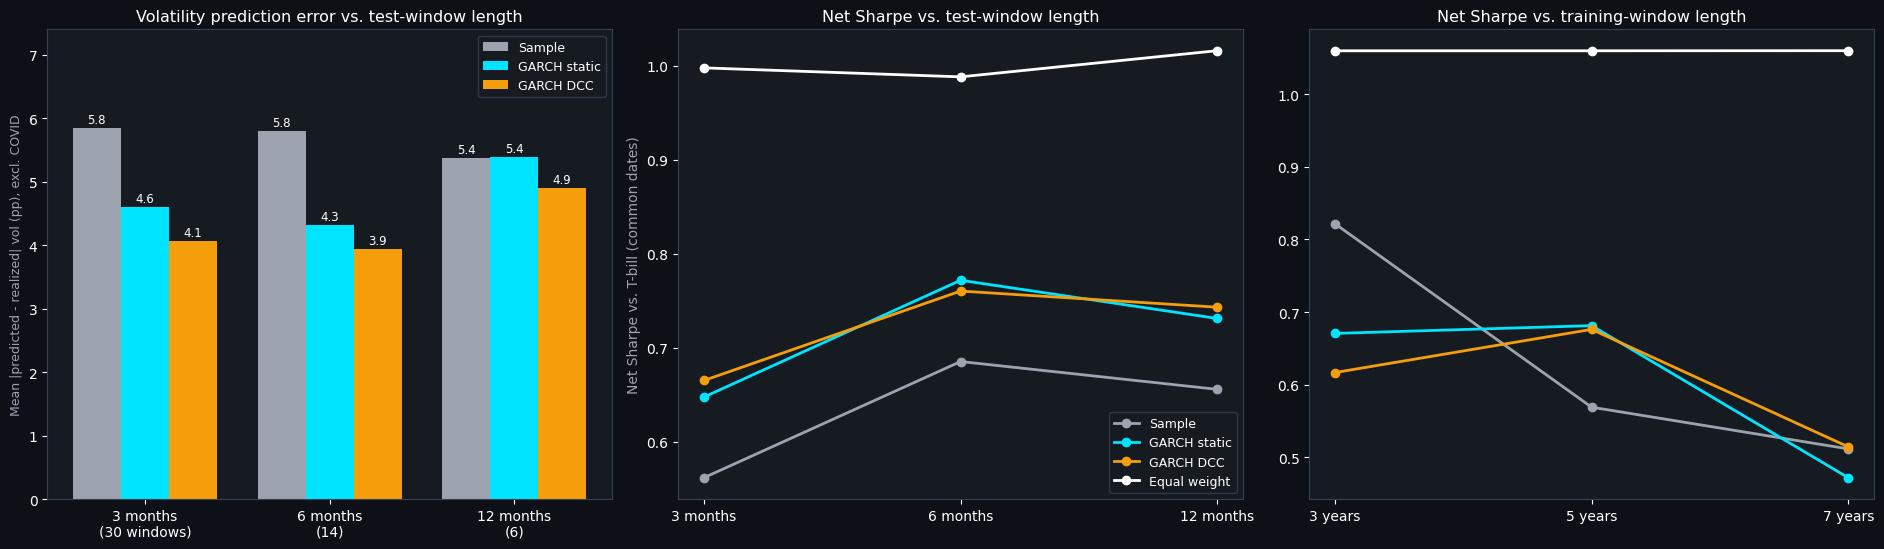

Saved chart_part8_window_length.png


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.6))
fig.patch.set_facecolor('#0d1117')
for ax in axes:
    ax.set_facecolor('#161b22')
    ax.tick_params(colors='white')
    for spine in ax.spines.values():
        spine.set_edgecolor('#374151')
cols = {'Sample': '#9ca3af', 'GARCH static': '#00e5ff', 'GARCH DCC': '#f59e0b', 'Equal weight': '#ffffff'}
ax = axes[0]
test_cfgs = ['test 3m / train 5y', 'test 6m / train 5y', 'test 12m / train 5y']
x = np.arange(3)
w = 0.26
sub = voltab[voltab.windows == 'excluding COVID window'].set_index('config')
for i, (lab, col) in enumerate((('Sample', '#9ca3af'), ('GARCH static', '#00e5ff'), ('GARCH DCC', '#f59e0b'))):
    vals = [sub.loc[c, f'{lab} error %'] for c in test_cfgs]
    bars = ax.bar(x + (i - 1) * w, vals, w, color=col, label=lab)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + 0.08, f'{v:.1f}', ha='center', fontsize=8.5, color='white')
ax.set_xticks(x)
ax.set_xticklabels(['3 months\n(%d windows)' % int(sub.loc[test_cfgs[0], 'n']), '6 months\n(%d)' % int(sub.loc[test_cfgs[1], 'n']), '12 months\n(%d)' % int(sub.loc[test_cfgs[2], 'n'])], color='white')
ax.set_ylabel('Mean |predicted - realized| vol (pp), excl. COVID', color='#9ca3af', fontsize=9)
ax.set_title('Volatility prediction error vs. test-window length', color='white', fontsize=11.5)
ax.set_ylim(0, 7.4)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=9)
ax = axes[1]
g = perf[perf.group == 'test-window length (5y training)']
for label, col in cols.items():
    s = g[g.strategy == label]
    ax.plot(range(3), [s[s.config == c]['sharpe'].iloc[0] for c in test_cfgs], marker='o', color=col, lw=2, label=label)
ax.set_xticks(range(3))
ax.set_xticklabels(['3 months', '6 months', '12 months'], color='white')
ax.set_ylabel('Net Sharpe vs. T-bill (common dates)', color='#9ca3af')
ax.set_title('Net Sharpe vs. test-window length', color='white', fontsize=11.5)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=9)
ax = axes[2]
train_cfgs = ['test 6m / train 3y', 'test 6m / train 5y', 'test 6m / train 7y']
g = perf[perf.group == 'training length (6m test)']
for label, col in cols.items():
    s = g[g.strategy == label]
    ax.plot(range(3), [s[s.config == c]['sharpe'].iloc[0] for c in train_cfgs], marker='o', color=col, lw=2, label=label)
ax.set_xticks(range(3))
ax.set_xticklabels(['3 years', '5 years', '7 years'], color='white')
ax.set_title('Net Sharpe vs. training-window length', color='white', fontsize=11.5)
plt.tight_layout()
plt.savefig('chart_part8_window_length.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print('Saved chart_part8_window_length.png')

## 6. Summary and saved tables

In [8]:
voltab.to_csv('part8_vol_error_by_window_length.csv', index=False)
perf.to_csv('part8_performance_by_window_length.csv', index=False)
drag.to_csv('part8_cost_drag.csv', index=False)
pd.concat([e.assign(config=n) for n, e in err.items()]).to_csv('part8_window_errors.csv', index=False)
print('=' * 70)
print('PART 8 SUMMARY: WINDOW LENGTH')
print('=' * 70)
print(voltab.to_string(index=False))
print()
print(perf.to_string(index=False))
print()
print('Files saved: chart_part8_window_length.png, part8_vol_error_by_window_length.csv, part8_performance_by_window_length.csv, part8_cost_drag.csv, part8_window_errors.csv')

PART 8 SUMMARY: WINDOW LENGTH
             config                windows  n  Sample error %  GARCH static error %  GARCH DCC error %  GARCH static wins  t (sample - GARCH static)  GARCH DCC wins  t (sample - GARCH DCC)
 test 3m / train 5y            all windows 31           7.034                 5.961              5.457                 20                      1.375              22                   1.925
 test 3m / train 5y excluding COVID window 30           5.849                 4.605              4.059                 20                      1.580              22                   2.187
 test 6m / train 5y            all windows 15           7.389                 6.238              5.927                 10                      1.178              11                   1.291
 test 6m / train 5y excluding COVID window 14           5.795                 4.317              3.940                 10                      1.494              11                   1.626
test 12m / train 5y      